# Tugas Pertemuan 9: Image Classification dengan Deep Learning

## Faizal Deshta Nugraha
## 2340506065

**Tugas:**
1. Cari data image classification di Kaggle
2. Buat arsitektur deep learning sederhana untuk kasus tersebut
3. Lakukan evaluasi dengan menghitung accuracy, precision, recall dan F1-score

## 1. Dataset

Dataset: **Rock-Paper-Scissors Images** dari Kaggle
https://www.kaggle.com/datasets/drgfreeman/rockpaperscissors
(Julien de la Bruère-Terreault, lisensi CC-BY-SA 4.0)

Dataset berisi foto gestur tangan permainan suit (batu-gunting-kertas) dengan latar belakang hijau, ukuran 300 x 200 piksel, format PNG. Terdapat 3 kelas:

| Kelas | Keterangan |
|---|---|
| `paper` | Telapak tangan terbuka (kertas) |
| `rock` | Tangan mengepal (batu) |
| `scissors` | Dua jari terbuka (gunting) |

Jika folder `dataset/` belum ada, sel di bawah akan mengunduh dataset dari Kaggle secara otomatis.

In [1]:
import os, re, random, time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| device:", device)

PyTorch: 2.15.0+cpu | device: cpu


In [2]:
import urllib.request, zipfile

DATA_DIR = "dataset"
CLASSES = ["paper", "rock", "scissors"]
KAGGLE_URL = "https://www.kaggle.com/api/v1/datasets/download/drgfreeman/rockpaperscissors"

# Unduh dataset dari Kaggle jika belum ada
if not all(os.path.isdir(os.path.join(DATA_DIR, c)) for c in CLASSES):
    print("Mengunduh dataset dari Kaggle ...")
    urllib.request.urlretrieve(KAGGLE_URL, "rps.zip")
    with zipfile.ZipFile("rps.zip") as z:
        for m in z.namelist():
            if m.split("/")[0] in CLASSES and not m.endswith("/"):
                z.extract(m, DATA_DIR)
    os.remove("rps.zip")

paths, labels = [], []
for idx, cls in enumerate(CLASSES):
    for f in sorted(os.listdir(os.path.join(DATA_DIR, cls))):
        paths.append(os.path.join(DATA_DIR, cls, f))
        labels.append(idx)
paths, labels = np.array(paths), np.array(labels)

print("Total citra :", len(paths))
for i, c in enumerate(CLASSES):
    print(f" - {c:9s}: {np.sum(labels == i)} citra")
print("Ukuran citra:", Image.open(paths[0]).size)

Total citra : 2188
 - paper    : 712 citra
 - rock     : 726 citra
 - scissors : 750 citra
Ukuran citra: (300, 200)


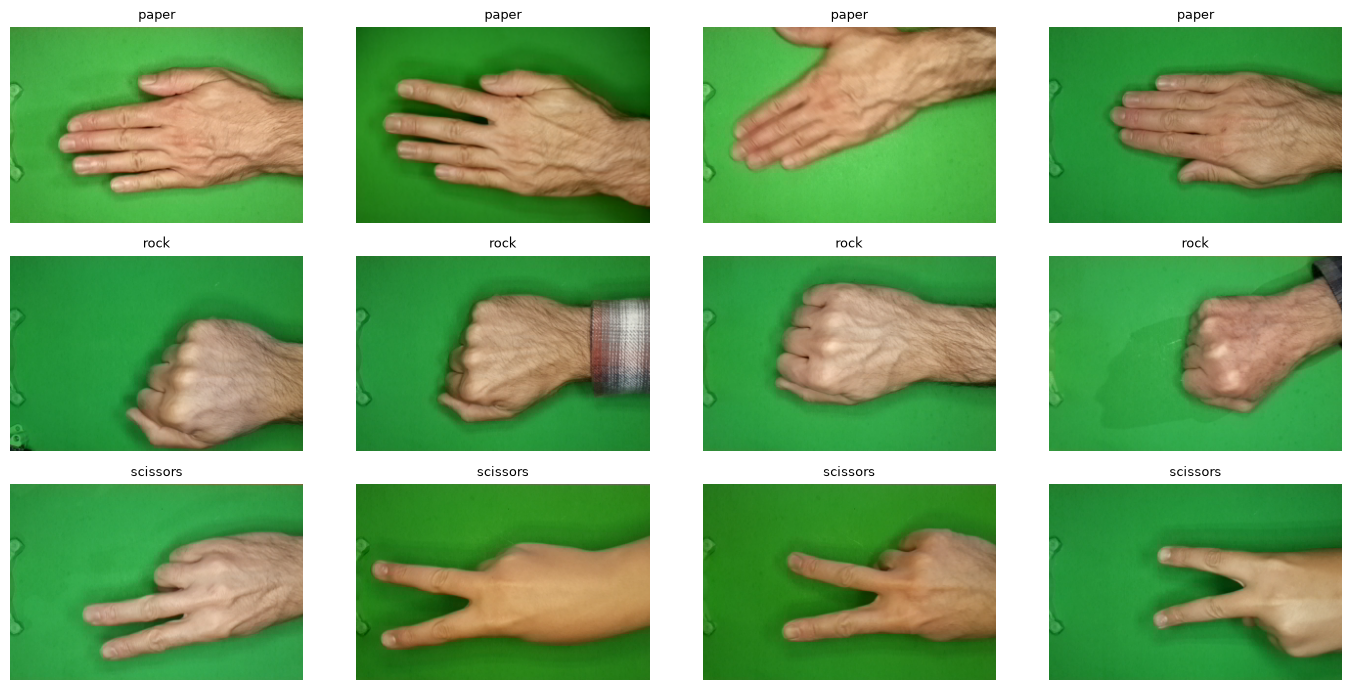

In [3]:
# Contoh citra tiap kelas
plt.figure(figsize=(14, 7))
for i, cls in enumerate(CLASSES):
    idxs = np.where(labels == i)[0][:4]
    for j, k in enumerate(idxs):
        plt.subplot(3, 4, i * 4 + j + 1)
        plt.imshow(Image.open(paths[k]).convert("RGB"))
        plt.title(cls, fontsize=9)
        plt.axis("off")
plt.tight_layout()
plt.show()

### Pembagian Data (Train / Validation / Test)

Data dibagi secara *stratified* (proporsi tiap kelas sama di setiap subset): **70% train, 15% validation, 15% test**. Data test tidak dipakai sama sekali selama training.

In [4]:
all_idx = np.arange(len(paths))
train_idx, temp_idx = train_test_split(all_idx, test_size=0.30, stratify=labels, random_state=SEED)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, stratify=labels[temp_idx], random_state=SEED)

for name, idx in [("Train", train_idx), ("Validation", val_idx), ("Test", test_idx)]:
    counts = [int(np.sum(labels[idx] == i)) for i in range(len(CLASSES))]
    print(f"{name:10s}: {len(idx):3d} citra | per kelas {dict(zip(CLASSES, counts))}")

Train     : 1531 citra | per kelas {'paper': 498, 'rock': 508, 'scissors': 525}
Validation: 328 citra | per kelas {'paper': 107, 'rock': 109, 'scissors': 112}
Test      : 329 citra | per kelas {'paper': 107, 'rock': 109, 'scissors': 113}


### Preprocessing & Augmentasi

- Semua citra di-*resize* dari 300 x 200 menjadi **150 x 100** piksel (rasio tetap 3:2) agar training lebih cepat, lalu dinormalisasi ke rentang [-1, 1].
- Data train diberi augmentasi ringan (*random crop*, *flip*, rotasi, perubahan kecerahan) agar model tidak mudah *overfitting*.

In [5]:
IMG_SIZE = (100, 150)   # (tinggi, lebar)
normalize = transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0), ratio=(1.3, 1.7)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    normalize,
])
eval_tf = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
    normalize,
])

class RPSDataset(Dataset):
    def __init__(self, idx, transform):
        self.paths, self.labels, self.transform = paths[idx], labels[idx], transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.transform(img), int(self.labels[i])

g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(RPSDataset(train_idx, train_tf), batch_size=32, shuffle=True, generator=g)
val_loader   = DataLoader(RPSDataset(val_idx, eval_tf),   batch_size=64)
test_loader  = DataLoader(RPSDataset(test_idx, eval_tf),  batch_size=64)

## 2. Arsitektur Deep Learning (CNN Sederhana)

Model berupa *Convolutional Neural Network* dengan 3 blok konvolusi:

```
Input (3 x 100 x 150)
 -> [Conv 3x3, 32]  -> BatchNorm -> ReLU -> MaxPool 2x2   => 32 x 50 x 75
 -> [Conv 3x3, 64]  -> BatchNorm -> ReLU -> MaxPool 2x2   => 64 x 25 x 37
 -> [Conv 3x3, 128] -> BatchNorm -> ReLU -> MaxPool 2x2   => 128 x 12 x 18
 -> Global Average Pooling                                 => 128
 -> Dropout(0.3) -> Fully Connected (128 -> 3)             => skor 3 kelas
```

- **Conv + ReLU** mengekstraksi fitur (tepi, tekstur, pola bercak).
- **BatchNorm** menstabilkan training, **MaxPool** memperkecil ukuran fitur.
- **Global Average Pooling + Dropout** membuat jumlah parameter kecil dan mengurangi *overfitting*, cocok untuk dataset kecil.
- Loss: **Cross-Entropy**, optimizer: **Adam** (lr = 0.001).

In [6]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()
        def block(c_in, c_out):
            return nn.Sequential(
                nn.Conv2d(c_in, c_out, kernel_size=3, padding=1),
                nn.BatchNorm2d(c_out),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
            )
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, num_classes))

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

model = SimpleCNN(len(CLASSES)).to(device)
print(model)
print("Jumlah parameter:", sum(p.numel() for p in model.parameters()))

SimpleCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  

## Training

Model dilatih 25 epoch. Bobot dengan *validation loss* terendah disimpan dan dipakai untuk evaluasi pada data test.

In [7]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
EPOCHS = 25

def run_epoch(loader, train=True):
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_loss, best_state = float("inf"), None
start = time.time()

for epoch in range(1, EPOCHS + 1):
    tl, ta = run_epoch(train_loader, train=True)
    vl, vacc = run_epoch(val_loader, train=False)
    for k, v in zip(history, (tl, vl, ta, vacc)):
        history[k].append(v)
    if vl < best_val_loss:
        best_val_loss = vl
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch {epoch:2d} | train loss {tl:.4f} acc {ta:.3f} | val loss {vl:.4f} acc {vacc:.3f}")

model.load_state_dict(best_state)
print(f"Selesai dalam {time.time() - start:.1f} detik. Best val loss = {best_val_loss:.4f}")

Epoch  1 | train loss 0.8210 acc 0.692 | val loss 1.0559 acc 0.576
Epoch  5 | train loss 0.2623 acc 0.939 | val loss 0.3582 acc 0.909
Epoch 10 | train loss 0.1577 acc 0.958 | val loss 0.2180 acc 0.927
Epoch 15 | train loss 0.1129 acc 0.973 | val loss 0.0995 acc 0.982
Epoch 20 | train loss 0.1072 acc 0.973 | val loss 0.1555 acc 0.960
Epoch 25 | train loss 0.0988 acc 0.973 | val loss 0.1229 acc 0.976
Selesai dalam 792.1 detik. Best val loss = 0.0743


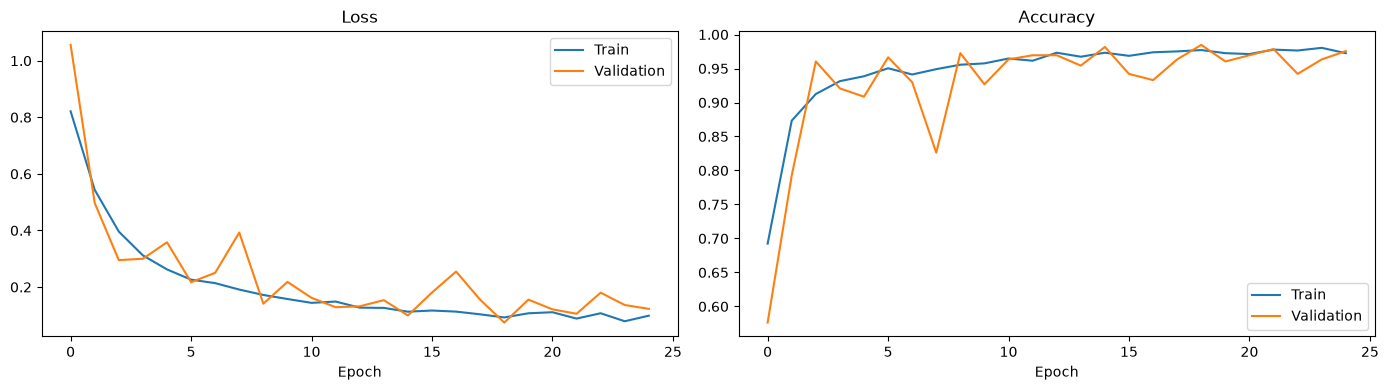

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(history["train_loss"], label="Train")
axes[0].plot(history["val_loss"], label="Validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(history["train_acc"], label="Train")
axes[1].plot(history["val_acc"], label="Validation")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout()
plt.show()

## 3. Evaluasi pada Data Test

Untuk setiap kelas $c$ dihitung dari *confusion matrix*:

- $TP_c$ = citra kelas $c$ yang diprediksi $c$
- $FP_c$ = citra kelas lain yang diprediksi $c$
- $FN_c$ = citra kelas $c$ yang diprediksi kelas lain

$$\text{Accuracy} = \frac{\text{jumlah prediksi benar}}{\text{jumlah data}}$$

$$\text{Precision}_c = \frac{TP_c}{TP_c + FP_c} \qquad \text{Recall}_c = \frac{TP_c}{TP_c + FN_c} \qquad F1_c = 2 \times \frac{\text{Precision}_c \times \text{Recall}_c}{\text{Precision}_c + \text{Recall}_c}$$

Nilai keseluruhan menggunakan **macro average** (rata-rata dari semua kelas).

In [9]:
model.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for x, y in test_loader:
        y_pred += model(x.to(device)).argmax(1).cpu().tolist()
        y_true += y.tolist()
y_true, y_pred = np.array(y_true), np.array(y_pred)

cm = confusion_matrix(y_true, y_pred, labels=range(len(CLASSES)))

# Perhitungan manual dari confusion matrix
print(f"{'Kelas':15s} | {'TP':>3} | {'FP':>3} | {'FN':>3} | {'Precision':>9} | {'Recall':>6} | {'F1':>6}")
# (baris = label asli, kolom = prediksi)
print("-" * 64)
precs, recs, f1s = [], [], []
for i, c in enumerate(CLASSES):
    tp = cm[i, i]
    fp = cm[:, i].sum() - tp
    fn = cm[i, :].sum() - tp
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    f = 2 * p * r / (p + r) if p + r else 0.0
    precs.append(p); recs.append(r); f1s.append(f)
    print(f"{c:15s} | {tp:3d} | {fp:3d} | {fn:3d} | {p:9.4f} | {r:6.4f} | {f:6.4f}")

acc_manual = np.trace(cm) / cm.sum()
print("-" * 64)
print(f"Accuracy          : {acc_manual:.4f}")
print(f"Precision (macro) : {np.mean(precs):.4f}")
print(f"Recall (macro)    : {np.mean(recs):.4f}")
print(f"F1-score (macro)  : {np.mean(f1s):.4f}")

Kelas           |  TP |  FP |  FN | Precision | Recall |     F1
----------------------------------------------------------------
paper           | 106 |   0 |   1 |    1.0000 | 0.9907 | 0.9953
rock            | 108 |   1 |   1 |    0.9908 | 0.9908 | 0.9908
scissors        | 112 |   2 |   1 |    0.9825 | 0.9912 | 0.9868
----------------------------------------------------------------
Accuracy          : 0.9909
Precision (macro) : 0.9911
Recall (macro)    : 0.9909
F1-score (macro)  : 0.9910


In [10]:
# Verifikasi dengan scikit-learn
print("Accuracy          :", round(accuracy_score(y_true, y_pred), 4))
print("Precision (macro) :", round(precision_score(y_true, y_pred, average="macro", zero_division=0), 4))
print("Recall (macro)    :", round(recall_score(y_true, y_pred, average="macro", zero_division=0), 4))
print("F1-score (macro)  :", round(f1_score(y_true, y_pred, average="macro", zero_division=0), 4))
print()
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4, zero_division=0))

Accuracy          : 0.9909
Precision (macro) : 0.9911
Recall (macro)    : 0.9909
F1-score (macro)  : 0.991

              precision    recall  f1-score   support

       paper     1.0000    0.9907    0.9953       107
        rock     0.9908    0.9908    0.9908       109
    scissors     0.9825    0.9912    0.9868       113

    accuracy                         0.9909       329
   macro avg     0.9911    0.9909    0.9910       329
weighted avg     0.9909    0.9909    0.9909       329



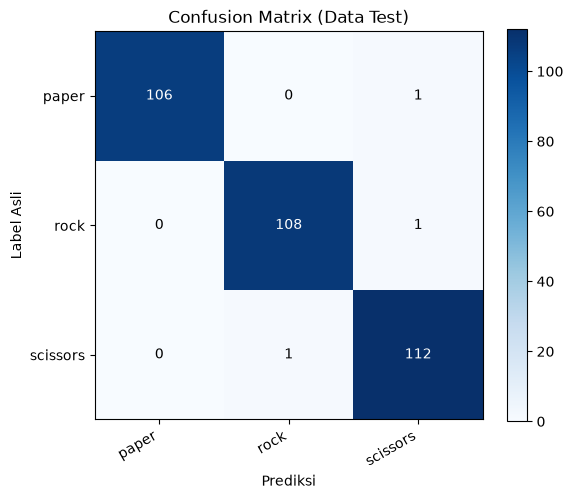

In [11]:
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(CLASSES, rotation=30, ha="right")
ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(CLASSES)
ax.set_xlabel("Prediksi"); ax.set_ylabel("Label Asli")
ax.set_title("Confusion Matrix (Data Test)")
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.colorbar(im)
plt.tight_layout()
plt.show()

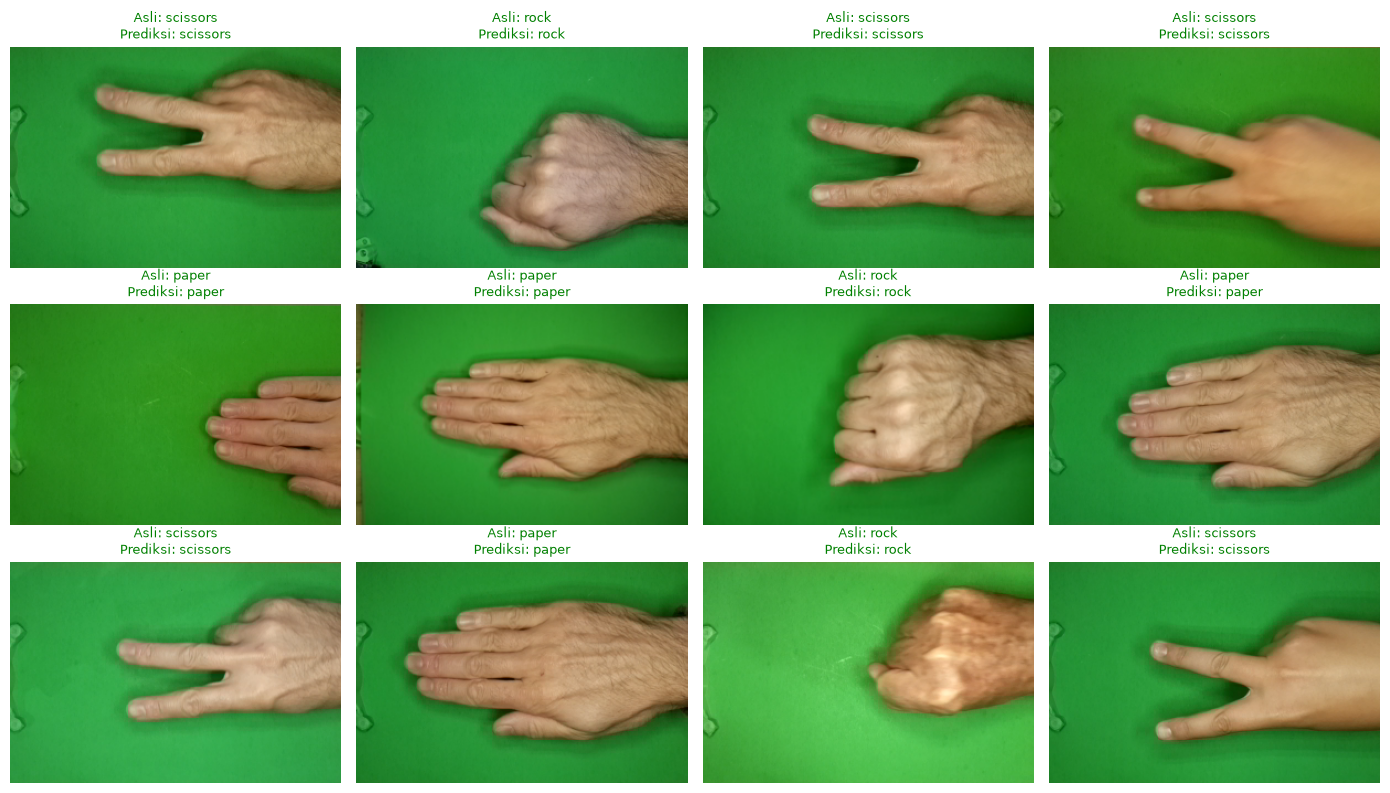

In [12]:
# Contoh hasil prediksi pada data test (hijau = benar, merah = salah)
show = np.random.RandomState(SEED).choice(len(test_idx), size=min(12, len(test_idx)), replace=False)
plt.figure(figsize=(14, 8))
for n, k in enumerate(show):
    plt.subplot(3, 4, n + 1)
    plt.imshow(Image.open(paths[test_idx[k]]).convert("RGB"))
    ok = y_true[k] == y_pred[k]
    plt.title(f"Asli: {CLASSES[y_true[k]]}\nPrediksi: {CLASSES[y_pred[k]]}",
              fontsize=9, color="green" if ok else "red")
    plt.axis("off")
plt.tight_layout()
plt.show()

## Kesimpulan

1. **Dataset:** Rock-Paper-Scissors dari Kaggle (2.188 citra, 3 kelas) dibagi menjadi 1.531 citra train, 328 validation, dan 329 test secara *stratified*.
2. **Arsitektur:** CNN sederhana dengan 3 blok konvolusi (32-64-128 filter), *Global Average Pooling*, dan *Dropout*, hanya **94.083 parameter**. Training 25 epoch di CPU memakan waktu sekitar 12 menit.
3. **Hasil evaluasi pada data test (329 citra):**

| Kelas | Precision | Recall | F1-score |
|---|---|---|---|
| paper | 1.0000 | 0.9907 | 0.9953 |
| rock | 0.9908 | 0.9908 | 0.9908 |
| scissors | 0.9825 | 0.9912 | 0.9868 |
| **Macro average** | **0.9911** | **0.9909** | **0.9910** |

   - **Accuracy = 99,09%** (326 dari 329 citra diprediksi benar, hanya 3 kesalahan).
   - Perhitungan manual dari *confusion matrix* menghasilkan nilai yang sama dengan `scikit-learn`.
4. **Analisis:** Kurva loss train dan validation turun bersamaan sehingga model tidak *overfitting*, dibantu oleh augmentasi data dan dropout. Nilai yang sangat tinggi juga dipengaruhi oleh kondisi dataset yang seragam (latar hijau, pencahayaan konsisten), sehingga performa model kemungkinan menurun jika diuji pada foto tangan dengan latar belakang lain.
